# Cookie Cats: разбор A/B-эксперимента по шагам
#
Ноутбук проходит тот же путь, что и контур: данные → EDA → статистика → сегменты →
CUPED → решение. Все расчёты — из модулей `src/experiment`, поэтому числа совпадают
с отчётом и тестами, а не живут отдельно.
#
Вопрос: стоит ли переносить первые «ворота» в игре с 30-го уровня на 40-й.
Данные: 90 189 игроков, `gate_30` (контроль) и `gate_40` (тест).

In [1]:
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy import stats as sps

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from experiment.advanced import cuped_adjust, cuped_variance_reduction, delta_ratio_diff
from experiment.power import mde_proportions, required_sample
from experiment.stats import diff_interval, holm, obf_boundaries, two_proportion_z, wilson_interval

FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 130, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})

CONTROL, TREATMENT = "gate_30", "gate_40"


def show(name: str) -> None:
    """Сохраняет и показывает рисунок — одинаково и в ноутбуке, и при прогоне скриптом."""
    path = FIG / name
    plt.savefig(path, bbox_inches="tight")
    plt.close()
    display(Image(filename=str(path)))


df = pd.read_csv(ROOT / "data" / "cookie_cats.csv")
for col in ("retention_1", "retention_7"):
    df[col] = df[col].astype(bool)
print(f"строк: {len(df):,} | групп: {df.version.value_counts().to_dict()}")

строк: 90,189 | групп: {'gate_40': 45489, 'gate_30': 44700}


## 1. EDA: что за данные и где подвох
#
Раунды распределены с тяжёлым хвостом: медиана 16, максимум — почти 50 тысяч.
Поэтому средние сравнивать нельзя без оговорок, а доля игроков с нулём раундов
сама по себе метрика оттока.

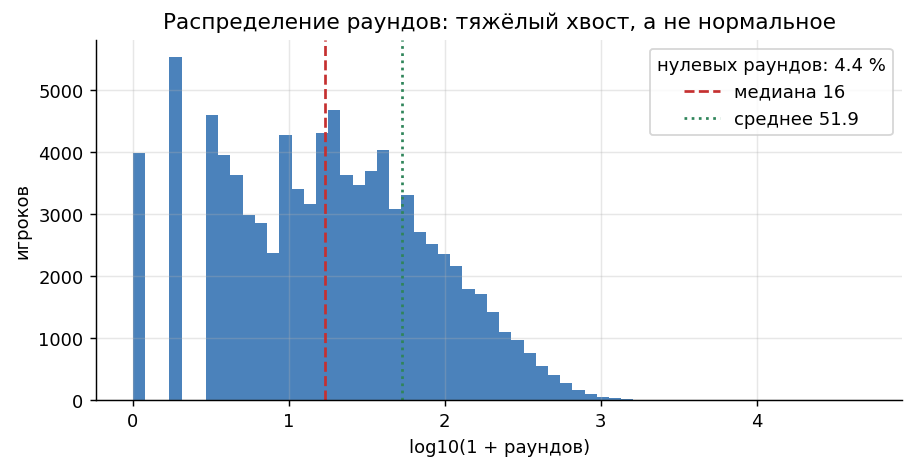

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.6))
log_rounds = np.log10(df.sum_gamerounds + 1)
ax.hist(log_rounds, bins=60, color="#2b6cb0", alpha=0.85)
ax.set_xlabel("log10(1 + раундов)")
ax.set_ylabel("игроков")
ax.set_title("Распределение раундов: тяжёлый хвост, а не нормальное")
zeros = (df.sum_gamerounds == 0).mean() * 100
ax.axvline(np.log10(df.sum_gamerounds.median() + 1), color="#c53030", linestyle="--",
           label=f"медиана {df.sum_gamerounds.median():.0f}")
ax.axvline(np.log10(df.sum_gamerounds.mean() + 1), color="#2f855a", linestyle=":",
           label=f"среднее {df.sum_gamerounds.mean():.1f}")
ax.legend(title=f"нулевых раундов: {zeros:.1f} %")
show("fig1_rounds.png")

In [3]:
print("раунды по группам")
print(df.groupby("version")["sum_gamerounds"].agg(["count", "mean", "median", "max"]).round(2).to_string())

раунды по группам
         count   mean  median    max
version                             
gate_30  44700  52.46    17.0  49854
gate_40  45489  51.30    16.0   2640


## 2. Удержание по группам с интервалами
#
Точки — доли, усы — интервалы Уилсона. Уже здесь видно, что разница маленькая:
интервалы почти соприкасаются.

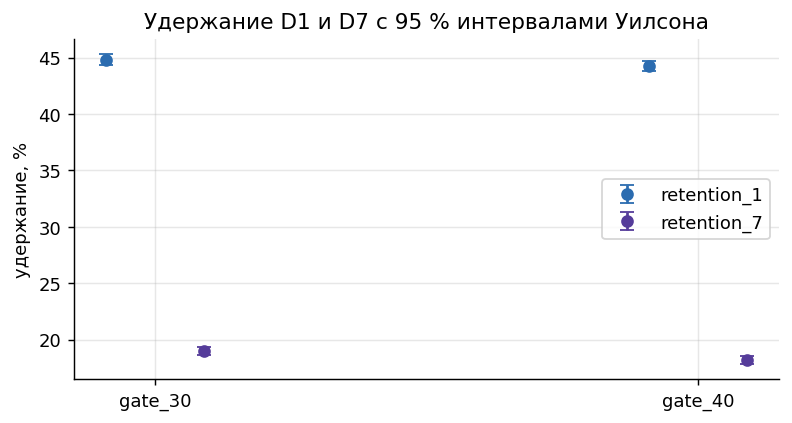

In [4]:
groups = [CONTROL, TREATMENT]
fig, ax = plt.subplots(figsize=(7, 3.4))
positions = np.arange(2)
for i, metric in enumerate(("retention_1", "retention_7")):
    rates, los, his = [], [], []
    for g in groups:
        k, n = int(df[df.version == g][metric].sum()), int((df.version == g).sum())
        lo, hi = wilson_interval(k, n)
        rates.append(k / n * 100)
        los.append(rates[-1] - lo * 100)
        his.append(hi * 100 - rates[-1])
    ax.errorbar(positions + (i - 0.5) * 0.18, rates, yerr=[los, his], fmt="o", capsize=4,
                label=metric, color="#2b6cb0" if i == 0 else "#553c9a")
ax.set_xticks(positions, groups)
ax.set_ylabel("удержание, %")
ax.set_title("Удержание D1 и D7 с 95 % интервалами Уилсона")
ax.legend()
show("fig2_retention.png")

## 3. Все эффекты на одной картинке
#
Forest plot: точка — разница, усы — 95 % интервал. Если усы пересекают ноль,
эффект не доказан. Хорошо видно, что D7 не пересекает, а D1 — пересекает.

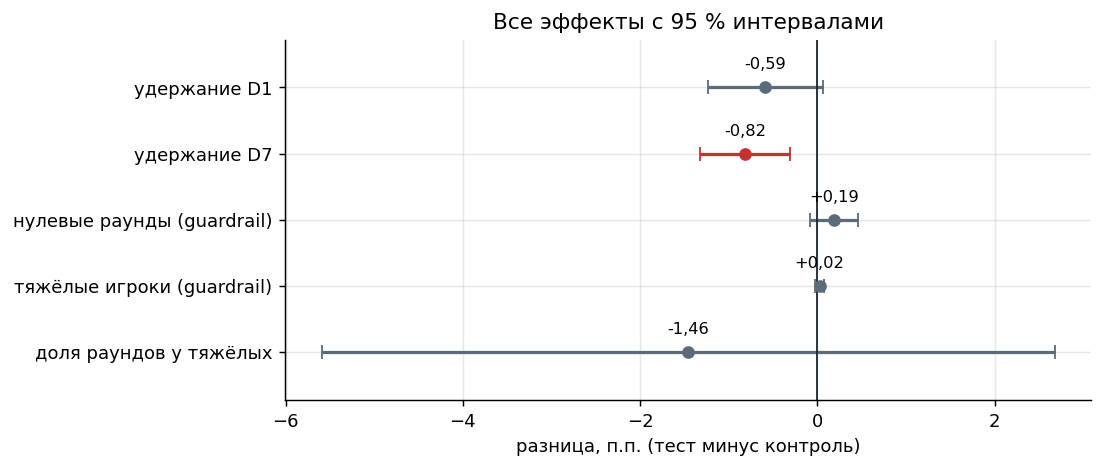

In [5]:
def rate_effect(metric: str) -> dict:
    c = df[df.version == CONTROL][metric]
    t = df[df.version == TREATMENT][metric]
    r = diff_interval(int(c.sum()), len(c), int(t.sum()), len(t))
    return {"diff": r["diff_pp"], "lo": r["diff_ci_pp"][0], "hi": r["diff_ci_pp"][1]}


df["zero_rounds"] = df.sum_gamerounds == 0
df["heavy_user"] = df.sum_gamerounds >= 1000
effects = {
    "удержание D1": rate_effect("retention_1"),
    "удержание D7": rate_effect("retention_7"),
    "нулевые раунды (guardrail)": rate_effect("zero_rounds"),
    "тяжёлые игроки (guardrail)": rate_effect("heavy_user"),
}

num_c = np.where(df[df.version == CONTROL].sum_gamerounds >= 1000, df[df.version == CONTROL].sum_gamerounds, 0.0)
num_t = np.where(df[df.version == TREATMENT].sum_gamerounds >= 1000, df[df.version == TREATMENT].sum_gamerounds, 0.0)
ratio = delta_ratio_diff(num_c, df[df.version == CONTROL].sum_gamerounds.values.astype(float),
                         num_t, df[df.version == TREATMENT].sum_gamerounds.values.astype(float))
effects["доля раундов у тяжёлых"] = {"diff": ratio["diff"] * 100,
                                     "lo": ratio["ci"][0] * 100, "hi": ratio["ci"][1] * 100}

fig, ax = plt.subplots(figsize=(8, 3.6))
names = list(effects)[::-1]
for i, name in enumerate(names):
    e = effects[name]
    color = "#c53030" if e["hi"] < 0 else ("#2f855a" if e["lo"] > 0 else "#5b6b7c")
    ax.errorbar(e["diff"], i, xerr=[[e["diff"] - e["lo"]], [e["hi"] - e["diff"]]],
                fmt="o", color=color, capsize=4, lw=1.8)
    ax.annotate(f"{e['diff']:+.2f}".replace(".", ","), (e["diff"], i),
                textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
ax.axvline(0, color="#1c2530", lw=1)
ax.set_yticks(range(len(names)), names)
ax.margins(y=0.18)
ax.set_xlabel("разница, п.п. (тест минус контроль)")
ax.set_title("Все эффекты с 95 % интервалами")
show("fig3_forest.png")

## 4. Планирование: сколько нужно игроков
#
Кривая MDE показывает, какой минимальный эффект различим при данном объёме.
Наш эксперимент — точка 45 000 на группу: различимы ~0,9 п.п. по D1.

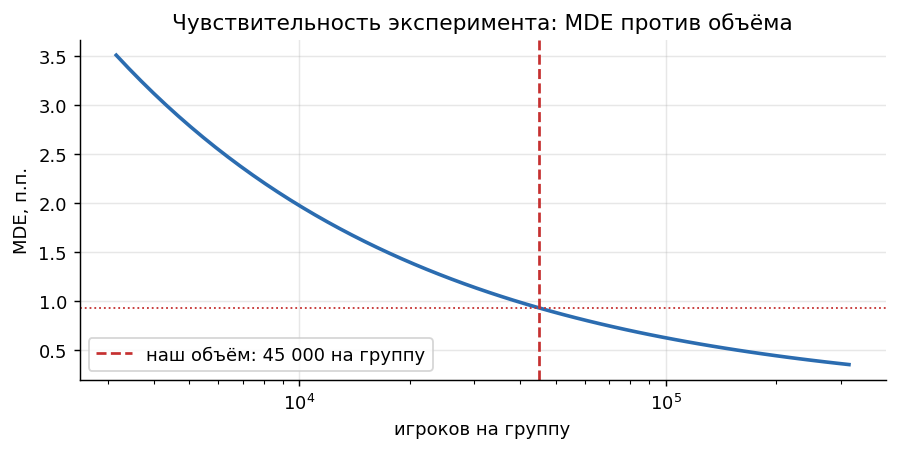

MDE при 45 000 на группу: 0.93 п.п. по D1
чтобы поймать 0,5 п.п.: нужно 155,280 на группу


In [6]:
sizes = np.logspace(3.5, 5.5, 60).astype(int)
mdes = [mde_proportions(0.448, int(n)) * 100 for n in sizes]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(sizes, mdes, color="#2b6cb0", lw=2)
ax.axvline(45000, color="#c53030", linestyle="--", label="наш объём: 45 000 на группу")
ax.axhline(mde_proportions(0.448, 45000) * 100, color="#c53030", linestyle=":", lw=1)
ax.set_xscale("log")
ax.set_xlabel("игроков на группу")
ax.set_ylabel("MDE, п.п.")
ax.set_title("Чувствительность эксперимента: MDE против объёма")
ax.legend()
show("fig4_mde.png")

print(f"MDE при 45 000 на группу: {mde_proportions(0.448, 45000) * 100:.2f} п.п. по D1")
print(f"чтобы поймать 0,5 п.п.: нужно {required_sample(0.448, 0.005):,} на группу")

## 5. Последовательный мониторинг
#
Смотреть в данные можно, если границы заданы заранее. Граница O'Brien–Fleming
падает с накоплением информации: ранние взгляды требуют очень сильного эффекта.

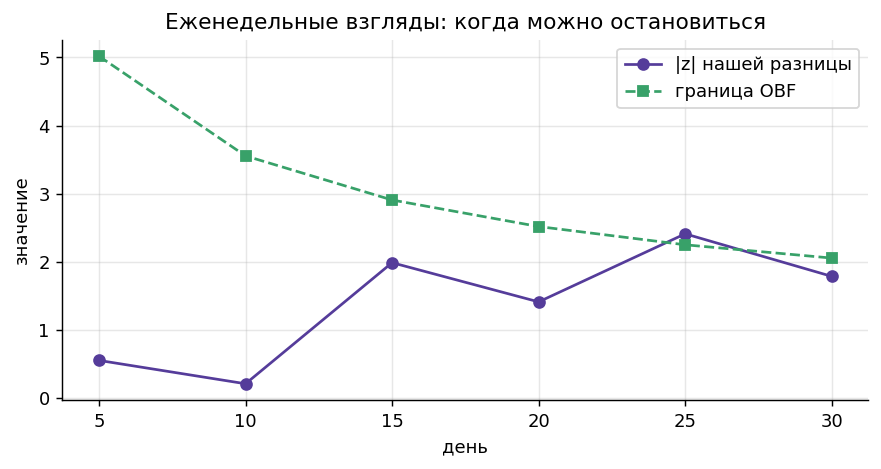

In [7]:
looks_path = ROOT / "results" / "sequential_looks.csv"
if looks_path.exists():
    looks = pd.read_csv(looks_path)
else:
    daily = pd.read_csv(ROOT / "results" / "daily_metrics.csv")
    looks = daily[daily.day.isin([5, 10, 15, 20, 25, 30])].copy()
    looks["boundary"] = obf_boundaries(looks.info_fraction.tolist())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(looks.day, looks.z.abs(), "o-", color="#553c9a", label="|z| нашей разницы")
ax.plot(looks.day, looks.boundary, "s--", color="#38a169", label="граница OBF")
ax.set_xlabel("день")
ax.set_ylabel("значение")
ax.set_title("Еженедельные взгляды: когда можно остановиться")
ax.legend()
show("fig5_sequential.png")

## 6. Как сужался интервал по мере накопления данных

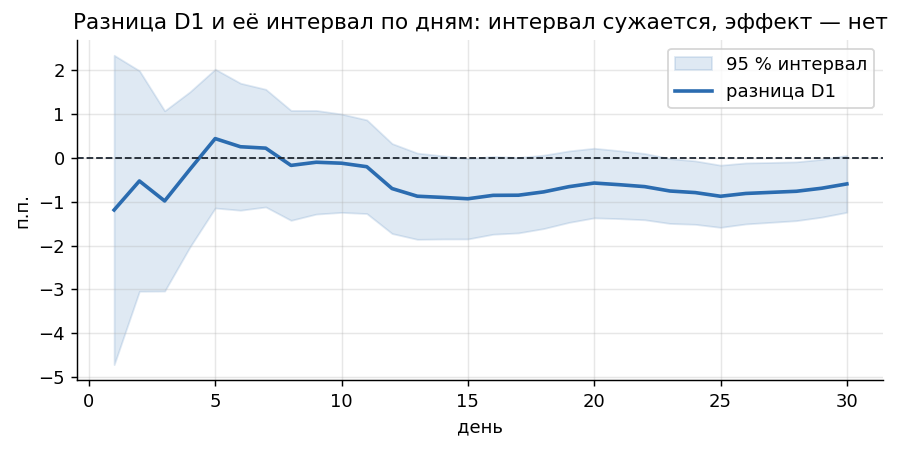

In [8]:
daily_full = pd.read_csv(ROOT / "results" / "daily_metrics.csv")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.fill_between(daily_full.day, daily_full.ci_lo_pp, daily_full.ci_hi_pp,
                color="#2b6cb0", alpha=0.15, label="95 % интервал")
ax.plot(daily_full.day, daily_full.diff_pp, color="#2b6cb0", lw=2, label="разница D1")
ax.axhline(0, color="#1c2530", lw=1, linestyle="--")
ax.set_xlabel("день")
ax.set_ylabel("п.п.")
ax.set_title("Разница D1 и её интервал по дням: интервал сужается, эффект — нет")
ax.legend()
show("fig6_daily.png")

## 7. Сегменты: эффект распределён или сконцентрирован
#
Если бы эффект был только в одном сегменте, это меняло бы решение. Поправка
Холма — потому что сегментов четыре, и «нашли в одном» — известная ловушка.

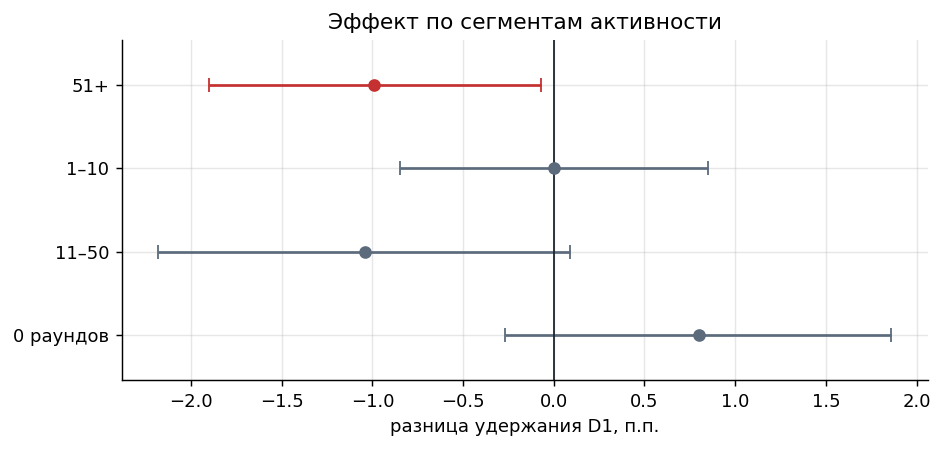

  segment  n_control  n_treatment  diff_pp  ci_lo  ci_hi  p_holm
0 раундов       5666         5879     0.80  -0.27   1.86  0.2848
    11–50      15078        14656    -1.04  -2.18   0.09  0.2136
     1–10      12987        13470     0.00  -0.85   0.85  0.9974
      51+      10969        11484    -0.99  -1.90  -0.07  0.1376


In [9]:
seg_path = ROOT / "results" / "segments.csv"
segments = pd.read_csv(seg_path)
analysed = segments[segments["note"].isna() | (segments["note"] == "")] if "note" in segments else segments

fig, ax = plt.subplots(figsize=(8, 3.4))
for i, row in enumerate(analysed.itertuples()):
    color = "#c53030" if row.ci_hi < 0 else ("#2f855a" if row.ci_lo > 0 else "#5b6b7c")
    ax.errorbar(row.diff_pp, i, xerr=[[row.diff_pp - row.ci_lo], [row.ci_hi - row.diff_pp]],
                fmt="o", color=color, capsize=4)
ax.axvline(0, color="#1c2530", lw=1)
ax.set_yticks(range(len(analysed)), list(analysed.segment))
ax.margins(y=0.18)
ax.set_xlabel("разница удержания D1, п.п.")
ax.set_title("Эффект по сегментам активности")
show("fig7_segments.png")

print(analysed[["segment", "n_control", "n_treatment", "diff_pp", "ci_lo", "ci_hi", "p_holm"]]
      .to_string(index=False))

## 8. CUPED: что дал бы предпериод
#
Предпериода в данных нет, поэтому показываем метод на синтетическом «до»:
снижение дисперсии должно совпасть с ρ² — это проверка, что реализация верна.

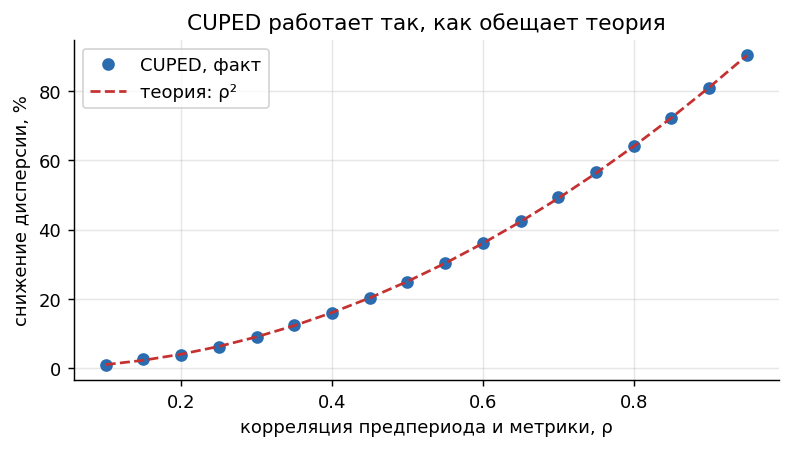

In [10]:
post = np.log1p(df.sum_gamerounds.to_numpy())
rhos = np.linspace(0.1, 0.95, 18)
reductions = []
rng = np.random.default_rng(42)
for rho in rhos:
    noise = rng.normal(0, np.std(post) * np.sqrt(1 - rho**2), len(post))
    pre = rho * (post - post.mean()) + post.mean() + noise
    reductions.append(cuped_variance_reduction(pre, post) * 100)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(rhos, reductions, "o", color="#2b6cb0", label="CUPED, факт")
ax.plot(rhos, rhos**2 * 100, "--", color="#c53030", label="теория: ρ²")
ax.set_xlabel("корреляция предпериода и метрики, ρ")
ax.set_ylabel("снижение дисперсии, %")
ax.set_title("CUPED работает так, как обещает теория")
ax.legend()
show("fig8_cuped.png")

## 9. Вывод
#
**Решение: ворота оставить на 30-м уровне.**
#
- Удержание D7: −0,82 п.п. [−1,33; −0,31], p после Холма 0,0032 и это выше MDE 0,7 п.п.
- Удержание D1: −0,59 п.п. [−1,24; +0,06] — интервал накрывает ноль, эффект ниже
  чувствительности 0,9 п.п., поэтому «не доказан», а не «отсутствует».
- Guardrails не сдвинулись, сегменты значимых различий не показали.
- Разница средних раундов −1,16 исчезает без одного игрока с 49 854 раундами (−0,04).

In [11]:
c = df[df.version == CONTROL].retention_7
t = df[df.version == TREATMENT].retention_7
r = diff_interval(int(c.sum()), len(c), int(t.sum()), len(t))
z, p = two_proportion_z(int(c.sum()), len(c), int(t.sum()), len(t))
adjusted = holm({"D1": 0.0744, "D7": p})

print(f"D7: {r['p1']*100:.2f} % → {r['p2']*100:.2f} %, разница {r['diff_pp']:+.2f} п.п. "
      f"[{r['diff_ci_pp'][0]:+.2f}; {r['diff_ci_pp'][1]:+.2f}]")
print(f"p = {p:.4f}, после Холма = {adjusted['D7']['p_holm']:.4f}")
print("Решение по плану: правило 3 — основная метрика значимо ухудшилась, оставить как было.")

D7: 19.02 % → 18.20 %, разница -0.82 п.п. [-1.33; -0.31]
p = 0.0016, после Холма = 0.0031
Решение по плану: правило 3 — основная метрика значимо ухудшилась, оставить как было.
